# QSO extended × DP2

Este notebook genera un análisis completo, fuera del dominio temporal, para `LaStBeRu_QSO_extended.csv`. El catálogo confirmado está contenido en él (511 filas con coincidencia exacta de nombre y coordenadas) y no se analiza por separado.

Se guardan: cobertura de visitas CCD individuales por banda, disponibilidad de coadds, profundidad y PSF, tablas por catálogo y `Status`, distribuciones, mapas del cielo coloreados por cantidad de visitas, mosaicos de coadds de 20″ × 20″ y FITS por banda.

La cobertura y los coadds se consultan para `extended` y se reutilizan mediante caches; todos los outputs quedan bajo la carpeta `extended`.

## 1. Configuración e imports

Esta celda define DP2, las colecciones, las bandas, las carpetas de salida y las caches. Los FITS se guardan fuera de la carpeta de resultados, en `/deleted-sundays/nowokaren/lastberu_qso_dp2_cutouts/fits`.

In [1]:
from pathlib import Path
import hashlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from target_selection import (
    build_cutout_pdf,
    build_collection_report_pdf,
    generate_collection_cutouts,
    load_collection_coadds,
    load_collection_coverage,
    open_collection,
    numeric_series,
)

numeric = numeric_series

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_release_config.py").exists()), Path.cwd())
DATA_DIR = REPO_ROOT / "data" / "LaStBeRu_data"
CATALOG_FILES = {"extended": DATA_DIR / "LaStBeRu_QSO_extended.csv"}
BANDS = tuple("ugrizy")
COLLECTION_NAME = "DP2"
COLLECTION = open_collection(COLLECTION_NAME)
RELEASE, tap_service, butler = COLLECTION.profile, COLLECTION.tap_service, COLLECTION.butler
OUTPUT_ROOT = REPO_ROOT / "notebooks" / "outputs" / "lastberu_qso_dp2"
CACHE_ROOT = OUTPUT_ROOT / "cache"
CUTOUT_ROOT = Path("/deleted-sundays/nowokaren/lastberu_qso_dp2_cutouts")
FITS_ROOT = CUTOUT_ROOT / "fits"
PNG_ROOT = CUTOUT_ROOT / "pngs"
CUTOUT_SIZE_ARCSEC = 20.0
SEARCH_RADIUS_DEG = 0.35
TILE_NSIDE = 64
TAP_WORKERS = 2
MAKE_CUTOUTS = True
for path in (OUTPUT_ROOT, CACHE_ROOT, FITS_ROOT, PNG_ROOT): path.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT

PosixPath('/home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2')

## 2. Carga y normalización de los catálogos

Se lee el CSV `extended`, se validan RA/DEC y se agrega `catalog` para conservar el origen. `target_id` incluye el nombre del catálogo.

In [2]:
frames = []
for catalog_name, path in CATALOG_FILES.items():
    if not path.exists(): raise FileNotFoundError(path)
    frame = pd.read_csv(path).copy()
    required = {"DB_JNAME", "RA", "DEC"}
    missing = required - set(frame.columns)
    if missing: raise ValueError(f"{path} no contiene {sorted(missing)}")
    frame["RA"] = pd.to_numeric(frame["RA"], errors="coerce")
    frame["DEC"] = pd.to_numeric(frame["DEC"], errors="coerce")
    frame = frame.dropna(subset=["DB_JNAME", "RA", "DEC"]).reset_index(drop=True)
    frame["catalog"] = catalog_name
    frame["Status"] = frame["Status"].map(lambda value: "unavailable" if pd.isna(value) else str(value).removesuffix(".0"))
    frame["catalog_index"] = np.arange(len(frame))
    frame["target_id"] = catalog_name + ":" + frame["DB_JNAME"].astype(str)
    frames.append(frame)
targets = pd.concat(frames, ignore_index=True)
canonical = targets[["target_id", "RA", "DEC"]].rename(columns={"RA":"ra_deg", "DEC":"dec_deg"})
print(f"Total targets extended: {len(targets):,}")
print(targets.groupby("Status", dropna=False).size().rename("n_targets"))


Total targets extended: 2,443
Status
0    1932
1     511
Name: n_targets, dtype: int64


## 3. Visitas individuales por banda

`query_visit_summary_by_band` consulta DP2 `VisitDetector` por tiles espaciales, recupera las filas detector-visita candidatas y verifica localmente la geometría de los cuatro vértices del detector. Se ejecuta una sola vez para el catálogo `extended`, usando la colección seleccionada en `COLLECTION_NAME`. Cada tile queda cacheada en `CACHE_ROOT/visit_tiles`, por lo que una interrupción puede reanudarse.

El resultado agregado tiene una fila por target y banda. También se conserva una tabla detallada con una fila por asociación target–visita–detector.

In [3]:
precomputed_coverage_path = OUTPUT_ROOT / "coverage_and_coadds_all.csv"
expected_ids = set(canonical["target_id"].astype(str))
if precomputed_coverage_path.exists():
    cached_coverage = pd.read_csv(precomputed_coverage_path)
    cached_ids = set(cached_coverage["target_id"].astype(str))
else:
    cached_coverage, cached_ids = None, set()

if cached_coverage is not None and expected_ids.issubset(cached_ids):
    coverage = cached_coverage.loc[cached_coverage["target_id"].astype(str).isin(expected_ids)].copy()
    print(f"Reutilizado sin consultar Butler: {len(coverage):,} targets desde {precomputed_coverage_path}")
else:
    coverage = load_collection_coverage(canonical, collection=COLLECTION.profile, tap_service=tap_service, tile_nside=TILE_NSIDE, max_workers=TAP_WORKERS, timeout_seconds=7200, search_radius_deg=SEARCH_RADIUS_DEG, cache_dir=CACHE_ROOT / "visit_coverage", bands=BANDS, verbose=True)
# Restore catalog metadata when coverage comes from a cache created without it.
metadata_columns = ["target_id", "catalog", "RA", "DEC"]
for optional_column in ("grade", "Status", "DB_JNAME"):
    if optional_column in targets.columns:
        metadata_columns.append(optional_column)
metadata = targets[metadata_columns].drop_duplicates("target_id")
coverage = coverage.drop(columns=[column for column in metadata_columns if column != "target_id" and column in coverage.columns], errors="ignore")
coverage = coverage.merge(metadata, on="target_id", how="left")



Reutilizado sin consultar Butler: 2,443 targets desde /home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/coverage_and_coadds_all.csv


## 4. Coadds y propiedades de calidad

Se comprueba en Butler si existe un coadd real para cada target con cobertura individual. La consulta directa se guarda en cache. Luego se muestrean, también con cache, los mapas consolidados de profundidad, PSF, tiempo de exposición y ruido de cielo. Esto evita repetir estas lecturas en futuras ejecuciones.

In [4]:
if "has_coadd" not in coverage.columns:
    coverage = load_collection_coadds(coverage, collection=COLLECTION.profile, butler=butler, cache_path=CACHE_ROOT / "direct_coadd_coverage.csv", reuse_cache=True, bands=BANDS, verbose=True)
else:
    print("Cobertura de coadds reutilizada desde el resultado completo.")

Cobertura de coadds reutilizada desde el resultado completo.


In [5]:
def numeric(frame, column):
    return pd.to_numeric(frame[column], errors="coerce") if column in frame else pd.Series(np.nan, index=frame.index)

property_columns = [f"coadd_maglim_{band}" for band in BANDS]
if not set(property_columns).issubset(coverage.columns):
    property_targets = coverage.loc[coverage.has_coadd, ["target_id", "ra_deg", "dec_deg"]].copy()
    property_key = hashlib.sha256("|".join(sorted(property_targets["target_id"].astype(str))).encode()).hexdigest()[:16]
    property_cache = CACHE_ROOT / f"coadd_properties_{property_key}.csv"
    if len(property_targets):
        if property_cache.exists():
            properties = pd.read_csv(property_cache)
            print(f"Reutilizado: {property_cache}")
        else:
            from target_selection.reference_catalog import sample_coadd_properties
            properties = sample_coadd_properties(property_targets, butler=butler, bands=BANDS, property_maps=("maglim", "psf_size", "exposure_time", "sky_noise"), partial_reads=True, verbose=True)
            properties.to_csv(property_cache, index=False)
        coverage = coverage.merge(properties, on="target_id", how="left", suffixes=("", "_map"))
else:
    print("Propiedades de coadds reutilizadas desde el resultado completo.")
for band in BANDS:
    maglim_values = pd.to_numeric(coverage[f"coadd_maglim_{band}"], errors="coerce") if f"coadd_maglim_{band}" in coverage else pd.Series(np.nan, index=coverage.index)
    psf_values = pd.to_numeric(coverage[f"coadd_psf_fwhm_arcsec_{band}"], errors="coerce") if f"coadd_psf_fwhm_arcsec_{band}" in coverage else pd.Series(np.nan, index=coverage.index)
    metric_mask = maglim_values.notna() & psf_values.notna()
    coverage[f"has_valid_coadd_{band}"] = coverage[f"has_coadd_{band}"].fillna(False).astype(bool) & metric_mask
coverage["has_valid_coadd"] = coverage[[f"has_valid_coadd_{band}" for band in BANDS]].any(axis=1)
coverage["valid_coadd_n_bands"] = coverage[[f"has_valid_coadd_{band}" for band in BANDS]].sum(axis=1).astype(int)
coverage = coverage.loc[:, ~coverage.columns.astype(str).str.startswith("Unnamed:")]
coverage.to_csv(OUTPUT_ROOT / "coverage_and_coadds_all.csv", index=False)
print(f"Targets with coadd coverage: {coverage.has_coadd.sum():,}/{len(coverage):,}")

Propiedades de coadds reutilizadas desde el resultado completo.
Targets with coadd coverage: 299/2,443


## 5. Separación de resultados y tablas resumen

A partir de `coverage_and_coadds_all.csv` se generan, sin nuevas consultas, los archivos de `extended`. `summary_by_band.csv` responde cobertura e imágenes por filtro; `summary_by_status.csv` resume la información por categoría `Status`. También se guarda el catálogo completo de cada grupo.

In [6]:
def numeric(frame, column):
    return pd.to_numeric(frame[column], errors="coerce") if column in frame else pd.Series(np.nan, index=frame.index)

def write_summaries(group, name, out):
    group = group.copy()
    group = group.loc[:, ~group.columns.astype(str).str.startswith("Unnamed:")]
    rows = []
    for status in sorted(group["Status"].dropna().unique(), key=str):
        subset = group.loc[group["Status"].eq(status)]
        label = f"Status={status}"
        rows.append({"status": label, "type": "visits", "total": int(subset["has_visit_coverage"].fillna(False).astype(bool).sum()), **{band: int(numeric(subset, f"n_images_{band}").fillna(0).gt(0).sum()) for band in BANDS}})
        rows.append({"status": label, "type": "coadds_found", "total": int(subset["has_coadd"].fillna(False).astype(bool).sum()), **{band: int(subset[f"has_coadd_{band}"].fillna(False).astype(bool).sum()) for band in BANDS}})
        rows.append({"status": label, "type": "coadds_with_valid_metrics", "total": int(subset["has_valid_coadd"].fillna(False).astype(bool).sum()), **{band: int(subset[f"has_valid_coadd_{band}"].fillna(False).astype(bool).sum()) for band in BANDS}})
    summary = pd.DataFrame(rows, columns=["status", "type", "total", *BANDS])
    summary.to_csv(out / "summary_by_status.csv", index=False)
    band_rows = [{"band": band, "targets_with_visits": int(numeric(group, f"n_images_{band}").fillna(0).gt(0).sum()), "coadds_found": int(group[f"has_coadd_{band}"].fillna(False).astype(bool).sum()), "coadds_with_valid_metrics": int(group[f"has_valid_coadd_{band}"].fillna(False).astype(bool).sum())} for band in BANDS]
    band_rows.append({"band": "total", "targets_with_visits": int(group["has_visit_coverage"].fillna(False).astype(bool).sum()), "coadds_found": int(group["has_coadd"].fillna(False).astype(bool).sum()), "coadds_with_valid_metrics": int(group["has_valid_coadd"].fillna(False).astype(bool).sum())})
    band_summary = pd.DataFrame(band_rows)
    band_summary.to_csv(out / "summary_by_band.csv", index=False)
    shown_band = band_summary.rename(columns={"band": "Band", "targets_with_visits": "Targets with visits", "coadds_found": "Coadds found", "coadds_with_valid_metrics": "Coadds with valid metrics"}).copy()
    for column in shown_band.columns[1:]: shown_band[column] = shown_band[column].map(lambda value: f"{int(value):,}")
    fig, ax = plt.subplots(figsize=(7.0, 2.1), dpi=220); ax.axis("off")
    table = ax.table(cellText=shown_band.values, colLabels=list(shown_band.columns), cellLoc="center", loc="center", bbox=[0, 0, 1, .86]); table.auto_set_font_size(False); table.set_fontsize(7)
    for (row, column), cell in table.get_celld().items():
        cell.set_facecolor("white"); cell.set_edgecolor("black"); cell.set_linewidth(0); cell.PAD = .025
        if row == 0: cell.visible_edges = "TB"; cell.set_linewidth(.8); cell.set_text_props(weight="bold")
        elif row == len(shown_band): cell.visible_edges = "B"; cell.set_linewidth(.8)
    ax.set_title(f"QSO × DP2 — {name}: coverage by band", fontsize=9, fontweight="bold", pad=2); fig.savefig(out / "summary_by_band.png", dpi=220, bbox_inches="tight", pad_inches=.02); plt.close(fig)
    group.to_csv(out / "coverage_and_coadds.csv", index=False)
    shown = summary.rename(columns={"status": "Status", "type": "Type", "total": "Total"}).copy()
    shown["Type"] = shown["Type"].map({"visits": "Visits", "coadds_found": "Coadds found", "coadds_with_valid_metrics": "Coadds with\nvalid metrics"})
    for column in shown.columns[2:]: shown[column] = shown[column].map(lambda value: f"{int(value):,}")
    fig, ax = plt.subplots(figsize=(7.0, 2.6), dpi=220); ax.axis("off")
    table = ax.table(cellText=shown.values, colLabels=list(shown.columns), cellLoc="center", loc="center", bbox=[0, 0, 1, .86])
    table.auto_set_font_size(False); table.set_fontsize(6.5)
    for (row, column), cell in table.get_celld().items():
        cell.set_facecolor("white"); cell.set_edgecolor("black"); cell.set_linewidth(0); cell.PAD = .025
        if row == 0: cell.visible_edges = "TB"; cell.set_linewidth(.8); cell.set_text_props(weight="bold")
        elif row == len(shown): cell.visible_edges = "B"; cell.set_linewidth(.8)
        if column == 0 and row > 0: cell.set_text_props(weight="bold")
    ax.set_title(f"QSO × DP2 — {name}: visits and coadds", fontsize=9, fontweight="bold", pad=2)
    fig.savefig(out / "summary_by_status.png", dpi=220, bbox_inches="tight", pad_inches=.02); plt.close(fig)
    return summary

summaries = {}
for name in ("extended",):
    folder = OUTPUT_ROOT / name; folder.mkdir(exist_ok=True)
    summaries[name] = write_summaries(coverage.loc[coverage.catalog.eq(name)].copy(), name, folder)
    print(f"{name}: {len(coverage.loc[coverage.catalog.eq(name)]):,} targets; outputs in {folder}")

extended: 2,443 targets; outputs in /home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended


In [7]:
coverage.loc[coverage.catalog.eq(name)][["Status", "n_images_u"]]

,Status,n_images_u
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0
...,...,...
2438,0,0
2439,0,0
2440,0,0
2441,0,0


## 6. Distribuciones

Para cada catálogo se guardan histogramas de visitas individuales, filtros con visitas, filtros con coadd, profundidad promedio y PSF promedio. Los valores se calculan usando el catálogo ya enriquecido.

In [8]:
from pathlib import Path
import shutil
from target_selection.reporting import add_cutout_status_columns, plot_collection_distributions

for name in ("extended",):
    distribution_group = coverage.loc[coverage.catalog.eq(name)].copy()
    distribution_group = add_cutout_status_columns(distribution_group, OUTPUT_ROOT / name / "cutout_manifest.csv", bands=BANDS)
    plot_collection_distributions(distribution_group, OUTPUT_ROOT / name, bands=BANDS, category_column="Status", category_label="Status", name="QSO × DP2")
    source = OUTPUT_ROOT / name / "distributions_by_Status.png"
    if source.exists() and source.resolve() != (OUTPUT_ROOT / name / "distributions_by_category.png").resolve(): shutil.copy2(source, OUTPUT_ROOT / name / "distributions_by_category.png")


## 7. Mapas del cielo

Cada punto corresponde a un target. El color representa la cantidad de visitas individuales; se guarda un mapa total y uno por banda para cada catálogo. Se usa una escala logarítmica cuando hay valores positivos para distinguir targets con pocas y muchas visitas.

In [9]:
from matplotlib.colors import LogNorm

def save_map(frame, count_col, path, title):
    values = numeric(frame, count_col).fillna(0)
    fig, ax = plt.subplots(figsize=(10, 5), dpi=180)
    if values.max() > 0:
        sc = ax.scatter(frame.RA % 360, frame.DEC, c=values, s=7, cmap="viridis", norm=LogNorm(vmin=1, vmax=max(1, values.max())), linewidths=0)
    else: sc = ax.scatter(frame.RA % 360, frame.DEC, c=values, s=7, cmap="viridis", linewidths=0)
    ax.invert_xaxis(); ax.grid(alpha=.2); ax.set(xlabel="RA [deg]", ylabel="DEC [deg]", title=title); fig.colorbar(sc, ax=ax, label="Individual visits"); fig.tight_layout(); fig.savefig(path, bbox_inches="tight"); plt.close(fig)

for name in ("extended",):
    g = coverage.loc[coverage.catalog.eq(name)]
    save_map(g, "n_images_total", OUTPUT_ROOT / name / "sky_map_visits_total.png", f"{name} — individual total visits")
    for b in BANDS: save_map(g, f"n_images_{b}", OUTPUT_ROOT / name / f"sky_map_visits_{b}.png", f"{name} — individual total visits in {b}")


## 8. Mosaicos de coadds y archivos FITS

Se usa `generate_collection_cutouts`, que delega en `save_coadd_cutout_grid` y carga los coadds disponibles y genera un mosaico de seis paneles de 20″ × 20″, uno por banda disponible. Se procesa `extended` y los FITS se escriben en `/deleted-sundays/nowokaren/lastberu_qso_dp2_cutouts`. El manifiesto relaciona cada target con su mosaico, cantidad de bandas y estado.


In [10]:
if MAKE_CUTOUTS:
    manifest = generate_collection_cutouts(
        coverage, collection=COLLECTION.profile, butler=butler,
        output_dir=PNG_ROOT, fits_dir=FITS_ROOT,
        bands=BANDS, size_arcsec=CUTOUT_SIZE_ARCSEC, catalog_name="extended", filename_prefix_column="Status", manifest_path=OUTPUT_ROOT / "extended" / "cutout_manifest.csv", add_rgb=False, reuse_existing=True, verbose=True,
    )
    manifest.to_csv(OUTPUT_ROOT / "extended" / "cutout_manifest.csv", index=False)
    print(f"Cutouts generated: {len(manifest):,}")

Cutouts extended:   0%|          | 0/299 [00:00<?, ?it/s]

Cutouts generated: 299


In [11]:
FITS_ROOT

PosixPath('/deleted-sundays/nowokaren/lastberu_qso_dp2_cutouts/fits')

## 10. Archivos finales

Al finalizar, los productos quedan organizados así:

```text
outputs/lastberu_qso_dp2/
├── │   ├── coverage_and_coadds.csv
│   ├── summary_by_band.csv
│   ├── summary_by_status.csv
│   ├── distributions.png
│   ├── sky_map_visits_*.png
│   ├── cutout_manifest.csv
│   ├── cutout_manifest.csv
│   └── (cutouts in delete_sundays/lastberu_cutouts/<catalog>/)
├── extended/
│   └── (misma estructura)
└── cache/

delete_sundays/lastberu_cutouts/
├── │   ├── fits/
│   ├── cutouts/
│   └── rgb/
└── extended/
    ├── fits/
    ├── cutouts/
```

The PDF is generated by the report cell in section 11. La consulta de cobertura puede reutilizarse dejando `reuse_cache=True`; para forzar una actualización habría que borrar o cambiar la cache correspondiente.

## 11. English PDF report

`build_collection_report_pdf` creates one report in this order: sky maps, distributions, summary tables, and one page per target with available coadd FITS and target metadata.

## Refresh summaries after cutout generation

This cell refreshes the summary tables after the cutout manifest has been written, including coadds with no valid pixels.


In [12]:
from target_selection.reporting import add_cutout_status_columns, plot_collection_distributions, write_collection_summaries
import shutil

summary_coverage = pd.read_csv(OUTPUT_ROOT / "extended" / "coverage_and_coadds.csv", low_memory=False)
summary_manifest = OUTPUT_ROOT / "extended" / "cutout_manifest.csv"
summary_group = summary_coverage.loc[summary_coverage["catalog"].eq("extended")].copy() if "catalog" in summary_coverage else summary_coverage
write_collection_summaries(summary_group, OUTPUT_ROOT / "extended", bands=BANDS, category_column="Status", category_label="Status", name="QSO extended × DP2", cutout_manifest=summary_manifest)
print("Summary tables and figures refreshed from the cutout manifest.")

distribution_group = add_cutout_status_columns(summary_group, summary_manifest, bands=BANDS)
plot_collection_distributions(distribution_group, OUTPUT_ROOT / "extended", bands=BANDS, category_column="Status", category_label="Status", name="QSO × DP2")
shutil.copy2(OUTPUT_ROOT / "extended" / "distributions_by_Status.png", OUTPUT_ROOT / "extended" / "distributions_by_category.png")


Summary tables and figures refreshed from the cutout manifest.


PosixPath('/home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/distributions_by_category.png')

In [13]:
extended = pd.read_csv(
    "outputs/lastberu_qso_dp2/extended/coverage_and_coadds.csv"
)

print("Extended status summary:")
display(extended.groupby("Status").agg(
    targets=("target_id", "size"),
    targets_with_visits=("n_images_total", lambda x: pd.to_numeric(x, errors="coerce").fillna(0).gt(0).sum()),
    targets_with_coadd=("has_coadd", "sum"),
))

Extended status summary:


,targets,targets_with_visits,targets_with_coadd
Status,,,
0,1932,754,250
1,511,183,49


## 12. Copy and rename existing QSO cutouts

This cell copies the previously generated FITS and PNG cutouts to the new shared location and renames them as `{status}_{target_id}_{band}`. Original files are not deleted.


## Refresh final summaries after retries

Run this after the retry section so the tables and PDF use the final cutout manifest.


In [14]:
from target_selection.reporting import add_cutout_status_columns, plot_collection_distributions, write_collection_summaries
import shutil

summary_coverage = pd.read_csv(OUTPUT_ROOT / "extended" / "coverage_and_coadds.csv", low_memory=False)
summary_manifest = OUTPUT_ROOT / "extended" / "cutout_manifest.csv"
summary_group = summary_coverage.loc[summary_coverage["catalog"].eq("extended")].copy() if "catalog" in summary_coverage else summary_coverage
write_collection_summaries(summary_group, OUTPUT_ROOT / "extended", bands=BANDS, category_column="Status", category_label="Status", name="QSO extended × DP2", cutout_manifest=summary_manifest)
print("Final summaries refreshed from the final cutout manifest.")

distribution_group = add_cutout_status_columns(summary_group, summary_manifest, bands=BANDS)
plot_collection_distributions(distribution_group, OUTPUT_ROOT / "extended", bands=BANDS, category_column="Status", category_label="Status", name="QSO × DP2")
shutil.copy2(OUTPUT_ROOT / "extended" / "distributions_by_Status.png", OUTPUT_ROOT / "extended" / "distributions_by_category.png")


Final summaries refreshed from the final cutout manifest.


PosixPath('/home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/distributions_by_category.png')

In [15]:
import re
import shutil

old_fits_dir = REPO_ROOT / "delete_sundays" / "lastberu_cutouts" / "extended" / "fits"
old_png_dir = REPO_ROOT / "delete_sundays" / "lastberu_cutouts" / "extended" / "cutouts"
new_fits_dir = FITS_ROOT
new_png_dir = PNG_ROOT
new_fits_dir.mkdir(parents=True, exist_ok=True)
new_png_dir.mkdir(parents=True, exist_ok=True)

qso_catalog = pd.read_csv(DATA_DIR / "LaStBeRu_QSO_extended.csv")
status_column = "status" if "status" in qso_catalog.columns else "Status"
id_column = "object_id" if "object_id" in qso_catalog.columns else "DB_JNAME"
status_by_id = dict(zip(qso_catalog[id_column].astype(str), qso_catalog[status_column].astype(str)))

def safe_status(value):
    value = str(value).strip()
    return value[:-2] if value.endswith(".0") else value

def safe_target(value):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value)).strip("_") or "target"

def copy_qso_product(source_path, destination_dir, suffix):
    name = source_path.stem
    if not name.startswith("extended_"):
        return None
    body = name.removeprefix("extended_")
    band = body[-1] if suffix == "fits" else None
    object_id = body[:-2] if suffix == "fits" else body.removesuffix("_coadds")
    status = status_by_id.get(object_id)
    if status is None:
        return {"source": str(source_path), "status": "not_in_catalog", "object_id": object_id}
    target_id = f"extended:{object_id}"
    prefix = safe_status(status)
    target_name = safe_target(target_id)
    destination_name = f"{prefix}_{target_name}_{band}.{suffix}" if suffix == "fits" else f"{prefix}_{target_name}_coadds.png"
    destination_path = destination_dir / destination_name
    if not destination_path.exists():
        shutil.copy2(source_path, destination_path)
    return {"source": str(source_path), "destination": str(destination_path), "status": prefix, "target_id": target_id, "band": band or ""}

records = []
if old_fits_dir.exists():
    for source_path in sorted(old_fits_dir.glob("*.fits")):
        record = copy_qso_product(source_path, new_fits_dir, "fits")
        if record: records.append(record)
if old_png_dir.exists():
    for source_path in sorted(old_png_dir.glob("*.png")):
        record = copy_qso_product(source_path, new_png_dir, "png")
        if record: records.append(record)

migration_manifest = pd.DataFrame(records)
migration_manifest.to_csv(OUTPUT_ROOT / "extended" / "cutout_migration_manifest.csv", index=False)
print(f"Processed FITS: {sum(bool(r.get('destination')) and str(r.get('source','')).endswith('.fits') for r in records):,}")
print(f"Processed PNGs: {sum(bool(r.get('destination')) and str(r.get('source','')).endswith('.png') for r in records):,}")
print(f"Manifest: {OUTPUT_ROOT / 'extended' / 'cutout_migration_manifest.csv'}")

# Rebuild the report after migration so the PDF uses the files in the new location.
pdf_path = build_collection_report_pdf(
    coverage, fits_dir=FITS_ROOT, asset_dir=OUTPUT_ROOT / "extended",
    output_path=OUTPUT_ROOT / "extended" / "extended_dp2_report.pdf", catalog_name="extended", bands=BANDS, manifest_path=OUTPUT_ROOT / "extended" / "cutout_manifest.csv", verbose=True,
)
print(f"Report PDF rebuilt: {pdf_path}")


Processed FITS: 0
Processed PNGs: 0
Manifest: /home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/cutout_migration_manifest.csv
Report target pages: 299 coadd targets; 2 currently without verified FITS.


Report target pages:   0%|          | 0/299 [00:00<?, ?it/s]

Report PDF rebuilt: /home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/extended_dp2_report.pdf


## Retry incomplete QSO cutouts

This standalone section can be run after a previous cutout attempt. It reloads the saved coverage and manifest, retries only targets whose registered coadd bands are not all present, and preserves detailed per-band diagnostics and complete tracebacks in the manifest.


In [16]:
from pathlib import Path
import pandas as pd

from target_selection import generate_collection_cutouts, open_collection

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_release_config.py").exists()), Path.cwd())
OUTPUT_ROOT = REPO_ROOT / "notebooks" / "outputs" / "lastberu_qso_dp2"
QSO_ROOT = OUTPUT_ROOT / "extended"
COVERAGE_PATH = QSO_ROOT / "coverage_and_coadds.csv"
MANIFEST_PATH = QSO_ROOT / "cutout_manifest.csv"
RETRY_MANIFEST_PATH = QSO_ROOT / "cutout_retry_manifest.csv"
FITS_ROOT = Path("/deleted-sundays/nowokaren/lastberu_qso_dp2_cutouts/fits")
PNG_ROOT = Path("/deleted-sundays/nowokaren/lastberu_qso_dp2_cutouts/pngs")
BANDS = tuple("ugrizy")

coverage_retry = pd.read_csv(COVERAGE_PATH, low_memory=False)
previous_manifest = pd.read_csv(MANIFEST_PATH, low_memory=False) if MANIFEST_PATH.exists() else pd.DataFrame()

if len(previous_manifest):
    expected_sets = previous_manifest["expected_bands"].fillna("").astype(str).str.split(",").map(lambda values: {band for band in values if band and band != "nan"})
    written_sets = previous_manifest["written_bands"].fillna("").astype(str).str.split(",").map(lambda values: {band for band in values if band and band != "nan"})
    complete = previous_manifest["png"].fillna("").astype(str).str.strip().ne("") & pd.Series([expected.issubset(written) for expected, written in zip(expected_sets, written_sets)], index=previous_manifest.index)
    incomplete_ids = set(previous_manifest.loc[~complete, "target_id"].astype(str))
    coverage_retry = coverage_retry.loc[coverage_retry["target_id"].astype(str).isin(incomplete_ids)].copy()
else:
    coverage_retry = coverage_retry.loc[coverage_retry["has_coadd"].fillna(False).astype(bool)].copy()

print(f"Retrying {len(coverage_retry):,} incomplete QSO targets.")
if len(coverage_retry):
    COLLECTION = open_collection("DP2")
    retry_manifest = generate_collection_cutouts(
        coverage_retry, collection=COLLECTION.profile, butler=COLLECTION.butler,
        output_dir=PNG_ROOT, fits_dir=FITS_ROOT, bands=BANDS, size_arcsec=20.0,
        catalog_name="extended", filename_prefix_column="Status", add_rgb=False,
        reuse_existing=True, manifest_path=RETRY_MANIFEST_PATH, verbose=True,
    )
    old = previous_manifest.loc[~previous_manifest["target_id"].astype(str).isin(set(retry_manifest["target_id"].astype(str)))] if len(previous_manifest) else pd.DataFrame()
    manifest = pd.concat([old, retry_manifest], ignore_index=True).sort_values("target_id")
    manifest.to_csv(MANIFEST_PATH, index=False)
    print(f"Updated manifest: {MANIFEST_PATH}")
    print(retry_manifest["status"].value_counts(dropna=False))
else:
    print("No incomplete QSO targets found.")


Retrying 6 incomplete QSO targets.


Cutouts extended:   0%|          | 0/6 [00:00<?, ?it/s]

Updated manifest: /home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/cutout_manifest.csv
status
partial            4
no_valid_cutout    2
Name: count, dtype: int64


In [17]:
pdf_path = build_collection_report_pdf(
    coverage, fits_dir=FITS_ROOT, asset_dir=OUTPUT_ROOT / "extended",
    output_path=OUTPUT_ROOT / "extended" / "extended_dp2_report.pdf", catalog_name="extended", bands=BANDS, manifest_path=OUTPUT_ROOT / "extended" / "cutout_manifest.csv", verbose=True,
)
print(f"Report PDF saved: {pdf_path}")

Report target pages: 299 coadd targets; 2 currently without verified FITS.


Report target pages:   0%|          | 0/299 [00:00<?, ?it/s]

Report PDF saved: /home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/extended_dp2_report.pdf


In [18]:
print("Main outputs — extended:")
for filename in ("coverage_and_coadds.csv", "summary_by_band.csv", "summary_by_status.csv", "distributions.png", "cutout_manifest.csv", "extended_dp2_report.pdf"):
    print(OUTPUT_ROOT / "extended" / filename)
print("FITS:", FITS_ROOT)
print("PNG cutouts:", PNG_ROOT)

Main outputs — extended:
/home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/coverage_and_coadds.csv
/home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/summary_by_band.csv
/home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/summary_by_status.csv
/home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/distributions.png
/home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/cutout_manifest.csv
/home/karennowo/target_selection/notebooks/outputs/lastberu_qso_dp2/extended/extended_dp2_report.pdf
FITS: /deleted-sundays/nowokaren/lastberu_qso_dp2_cutouts/fits
PNG cutouts: /deleted-sundays/nowokaren/lastberu_qso_dp2_cutouts/pngs


In [19]:
manifest[["target_id", "status", "error_type", "error_message", "error_traceback", "diagnostics_json"]]

,target_id,status,error_type,error_message,error_traceback,diagnostics_json
159,extended:DECALSJ0027-4753,reused,NaN,NaN,NaN,[]
166,extended:DECALSJ0041-0203,reused,NaN,NaN,NaN,[]
190,extended:DECALSJ0148+0204,reused,NaN,NaN,NaN,[]
197,extended:DECALSJ0343-4920,reused,NaN,NaN,NaN,[]
198,extended:DECALSJ0355-5036,reused,NaN,NaN,NaN,[]
...,...,...,...,...,...,...
234,extended:SDSSJ221729.41-081154.9,reused,NaN,NaN,NaN,[]
236,extended:SDSSJ221953.73-010037.5,reused,NaN,NaN,NaN,[]
255,extended:SDSSJ230951.18-094016.3,reused,NaN,NaN,NaN,[]
256,extended:SDSSJ2314-0108,reused,NaN,NaN,NaN,[]


In [20]:
for i, row in manifest[manifest["status"]!="generated"][["target_id", "status", "error_type", "error_message", 
                                                         "error_traceback", "diagnostics_json"]].iterrows():
    print("-------------------------------------------------------------------------------------------------")
    print(row["target_id"])
    print(row["error_type"])
    print(row["error_traceback"])

-------------------------------------------------------------------------------------------------
extended:DECALSJ0027-4753
nan
nan
-------------------------------------------------------------------------------------------------
extended:DECALSJ0041-0203
nan
nan
-------------------------------------------------------------------------------------------------
extended:DECALSJ0148+0204
nan
nan
-------------------------------------------------------------------------------------------------
extended:DECALSJ0343-4920
nan
nan
-------------------------------------------------------------------------------------------------
extended:DECALSJ0355-5036
nan
nan
-------------------------------------------------------------------------------------------------
extended:DECALSJ2238-1109
nan
nan
-------------------------------------------------------------------------------------------------
extended:DECALSJ2326-0104
nan
nan
----------------------------------------------------------------------------

## Diagnose an empty QSO cutout

This cell is independent of the full notebook run. It reproduces the original `ValueError` condition for one problematic target by measuring the finite pixels in each registered coadd cutout. The instrumented function now keeps the complete Butler/reference/WCS diagnostics and tries alternative references when available.


In [21]:
from pathlib import Path
import json
import pandas as pd

from target_selection import open_collection
from target_selection.reference_catalog import save_coadd_cutout_grid

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_release_config.py").exists()), Path.cwd())
QSO_ROOT = REPO_ROOT / "notebooks" / "outputs" / "lastberu_qso_dp2" / "extended"
coverage = pd.read_csv(QSO_ROOT / "coverage_and_coadds.csv", low_memory=False)
TARGET_ID = "extended:J135425.2-094102.8"
row = coverage.loc[coverage["target_id"].astype(str).eq(TARGET_ID)].iloc[0].copy()
if "ra_deg" not in row.index and "RA" in row.index:
    row["ra_deg"] = row["RA"]
if "dec_deg" not in row.index and "DEC" in row.index:
    row["dec_deg"] = row["DEC"]
expected_bands = [band for band in "ugrizy" if bool(row.get(f"has_coadd_{band}", False))]
print(f"Target: {TARGET_ID}; registered coadd bands: {expected_bands}")

COLLECTION = open_collection("DP2")
diagnostics = []
_, plotted = save_coadd_cutout_grid(
    row, butler=COLLECTION.butler, data_release=COLLECTION.profile,
    output_path=Path("/tmp/qso_empty_cutout_diagnostic.png"), bands=expected_bands,
    size_arcsec=20.0, save_fits=False, diagnostics=diagnostics,
)

diagnostic_table = pd.DataFrame(diagnostics)
columns = ["band", "status", "reference", "x", "y", "nx", "ny", "cutout_shape", "finite_pixels", "error_type", "error_message"]
print(f"Plotted bands after fallback search: {plotted}")
display(diagnostic_table[[column for column in columns if column in diagnostic_table]])

for record in diagnostics:
    if record.get("status") == "empty_cutout":
        print(f"Original failure condition reproduced for band {record['band']}: finite_pixels=0.")
    if record.get("traceback"):
        print(f"\nTraceback for {record['band']}:\n{record['traceback']}")


Target: extended:J135425.2-094102.8; registered coadd bands: ['r']
Plotted bands after fallback search: 0


,band,status,error_type,error_message
0,r,empty_cutout,empty_cutout,No usable coadd reference produced a cutout.


Original failure condition reproduced for band r: finite_pixels=0.


## Plot the registered coadds with the target position

This standalone cell displays the available 20-arcsec cutouts for the selected target and marks the target position with a red circle. It also tries alternative Butler references when the first reference is empty.


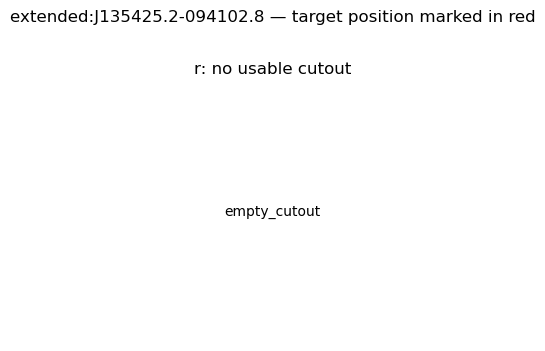

In [22]:
from pathlib import Path
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.visualization import AsinhStretch, ImageNormalize
from target_selection.reference_catalog import _data_id_value

TARGET_ID = "extended:J135425.2-094102.8"
#TARGET_ID = "extended:DECALSJ0041-0203"  #ejemplo valido
row = coverage.loc[coverage["target_id"].astype(str).eq(TARGET_ID)].iloc[0].copy()
if "ra_deg" not in row.index and "RA" in row.index:
    row["ra_deg"] = row["RA"]
if "dec_deg" not in row.index and "DEC" in row.index:
    row["dec_deg"] = row["DEC"]
expected_bands = [band for band in "ugrizy" if bool(row.get(f"has_coadd_{band}", False))]
coordinate = SkyCoord(float(row["ra_deg"]) * u.deg, float(row["dec_deg"]) * u.deg)
release = COLLECTION.profile
refs = []
for dataset_type in release.coadd_dataset_types:
    try:
        refs = list(COLLECTION.butler.query_datasets(dataset_type, where=release.coadd_spatial_where, bind={"ra": float(row["ra_deg"]), "dec": float(row["dec_deg"])}))
    except Exception as error:
        print(f"Dataset query failed for {dataset_type}: {type(error).__name__}: {error}")
    if refs:
        break

fig, axes = plt.subplots(1, max(1, len(expected_bands)), figsize=(3.2 * max(1, len(expected_bands)), 3.4), squeeze=False)
for axis, band in zip(axes.flat, expected_bands, strict=False):
    band_refs = [ref for ref in refs if str(_data_id_value(ref, "band", "")) == band]
    selected = None
    attempts = []
    for ref in band_refs:
        try:
            coadd = COLLECTION.butler.get(ref)
            x, y = coadd.fits_wcs.world_to_pixel(coordinate)
            image = coadd.image.array
            if hasattr(image, "filled"):
                image = image.filled(np.nan)
            ny, nx = image.shape
            if not (0 <= x < nx and 0 <= y < ny):
                attempts.append("outside_image")
                continue
            pixel_scale = float(np.mean([scale.to_value(u.arcsec) for scale in coadd.fits_wcs.proj_plane_pixel_scales()]))
            half_pixels = max(2, int(math.ceil(20.0 / (2 * pixel_scale))))
            x0, x1 = max(0, int(np.floor(x)) - half_pixels), min(nx, int(np.floor(x)) + half_pixels + 1)
            y0, y1 = max(0, int(np.floor(y)) - half_pixels), min(ny, int(np.floor(y)) + half_pixels + 1)
            cutout = np.asarray(image[y0:y1, x0:x1], dtype=float)
            finite = cutout[np.isfinite(cutout)]
            if not len(finite):
                attempts.append("empty_cutout")
                continue
            selected = (cutout, x, y, x0, x1, y0, y1, pixel_scale, finite, ref)
            break
        except Exception as error:
            attempts.append(f"{type(error).__name__}: {error}")
    if selected is None:
        axis.axis("off")
        axis.set_title(f"{band}: no usable cutout")
        axis.text(0.5, 0.5, "\n".join(attempts) or "No reference", ha="center", va="center", wrap=True)
        continue
    cutout, x, y, x0, x1, y0, y1, pixel_scale, finite, ref = selected
    extent = ((x0 - x) * pixel_scale, (x1 - x) * pixel_scale, (y0 - y) * pixel_scale, (y1 - y) * pixel_scale)
    norm = ImageNormalize(vmin=np.nanpercentile(finite, 5), vmax=np.nanpercentile(finite, 99.8), stretch=AsinhStretch(0.08), clip=True)
    axis.imshow(cutout, origin="lower", cmap="gray", norm=norm, extent=extent)
    axis.add_patch(Circle((0, 0), 0.8, edgecolor="red", facecolor="none", linewidth=1.5))
    axis.set_title(f"{band} — finite pixels: {len(finite):,}")
    axis.set_xlabel("x offset [arcsec]"); axis.set_ylabel("y offset [arcsec]")
fig.suptitle(f"{TARGET_ID} — target position marked in red", y=1.02)
fig.tight_layout()
plt.show()


## Explicit QSO coadd diagnostic: coverage to plotted cutout

This standalone cell executes and prints every stage for one target: catalog coverage, Butler spatial query, reference selection, Butler retrieval, WCS projection, footprint test, cutout extraction, finite-pixel validation, and plotting.


STAGE 1 — Target and coverage record
target_id: extended:J135425.2-094102.8
RA, DEC: 208.60500000, -9.68411000
has_coadd: True
coadd_bands: r
bands that will be queried: ['r']

STAGE 2 — Open DP2 Butler
collection profile: DP2
coadd dataset types: ('deep_coadd',)
spatial predicate: patch.region OVERLAPS POINT(:ra,:dec)

STAGE 3 — Spatial dataset query
deep_coadd: 1 reference(s)
band r: 1 reference(s)
  reference: r; dataId={band: 'r', skymap: 'lsst_cells_v2', tract: 7918, patch: 44}

STAGE 4 — Butler.get for full r-band coadd
Butler.get: SUCCESS
full image dtype: float64; full image shape: (3300, 3300)

STAGE 5 — WCS projection and full-image footprint test
target pixel position: x=1285.930141, y=2884.319605
full image bounds: 0 <= x < 3300, 0 <= y < 3300
target inside full coadd: True

STAGE 6 — Full coadd pixel validation
finite pixels: 0 / 10,890,000

STAGE 7 — Plot full coadd


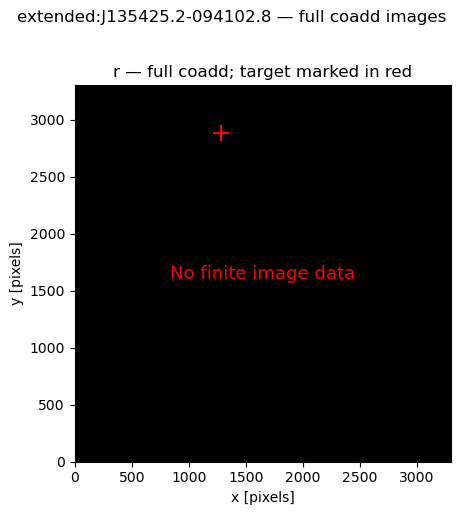

In [23]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.visualization import AsinhStretch, ImageNormalize

from target_selection import open_collection
from target_selection.reference_catalog import _data_id_value

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_release_config.py").exists()), Path.cwd())
TARGET_ID = "extended:J135425.2-094102.8"
BANDS = tuple("ugrizy")
QSO_ROOT = REPO_ROOT / "notebooks" / "outputs" / "lastberu_qso_dp2" / "extended"
coverage = pd.read_csv(QSO_ROOT / "coverage_and_coadds.csv", low_memory=False)
row = coverage.loc[coverage["target_id"].astype(str).eq(TARGET_ID)].iloc[0].copy()
if "ra_deg" not in row.index and "RA" in row.index:
    row["ra_deg"] = row["RA"]
if "dec_deg" not in row.index and "DEC" in row.index:
    row["dec_deg"] = row["DEC"]

print("STAGE 1 — Target and coverage record")
print(f"target_id: {TARGET_ID}")
print(f"RA, DEC: {float(row['ra_deg']):.8f}, {float(row['dec_deg']):.8f}")
print(f"has_coadd: {row.get('has_coadd')}")
print(f"coadd_bands: {row.get('coadd_bands')}")
registered_bands = [band for band in BANDS if bool(row.get(f"has_coadd_{band}", False))]
if not registered_bands and str(row.get("coadd_bands", "")).strip():
    registered_bands = [band.strip() for band in str(row["coadd_bands"]).split(",") if band.strip() in BANDS]
print(f"bands that will be queried: {registered_bands}")

print("\nSTAGE 2 — Open DP2 Butler")
COLLECTION_DIAGNOSTIC = open_collection("DP2")
release = COLLECTION_DIAGNOSTIC.profile
print(f"collection profile: {release.name}")
print(f"coadd dataset types: {release.coadd_dataset_types}")
print(f"spatial predicate: {release.coadd_spatial_where}")
coordinate = SkyCoord(float(row["ra_deg"]) * u.deg, float(row["dec_deg"]) * u.deg)

print("\nSTAGE 3 — Spatial dataset query")
refs = []
for dataset_type in release.coadd_dataset_types:
    try:
        candidate_refs = list(COLLECTION_DIAGNOSTIC.butler.query_datasets(dataset_type, where=release.coadd_spatial_where, bind={"ra": float(row["ra_deg"]), "dec": float(row["dec_deg"])}))
        print(f"{dataset_type}: {len(candidate_refs)} reference(s)")
        refs = candidate_refs
    except Exception as error:
        print(f"{dataset_type}: QUERY ERROR {type(error).__name__}: {error}")
        refs = []
    if refs:
        break

refs_by_band = {band: [ref for ref in refs if str(_data_id_value(ref, "band", "")) == band] for band in registered_bands}
for band, band_refs in refs_by_band.items():
    print(f"band {band}: {len(band_refs)} reference(s)")
    for ref in band_refs:
        print(f"  reference: {_data_id_value(ref, 'band', '')}; dataId={getattr(ref, 'dataId', ref)}")

fig, axes = plt.subplots(1, max(1, len(registered_bands)), figsize=(5.0 * max(1, len(registered_bands)), 5.0), squeeze=False)
for axis, band in zip(axes.flat, registered_bands, strict=False):
    print(f"\nSTAGE 4 — Butler.get for full {band}-band coadd")
    selected = None
    if not refs_by_band[band]:
        print("No Butler reference returned for this registered band.")
    for ref in refs_by_band[band]:
        try:
            coadd = COLLECTION_DIAGNOSTIC.butler.get(ref)
            print("Butler.get: SUCCESS")
            image = coadd.image.array
            if hasattr(image, "filled"):
                image = image.filled(np.nan)
            image = np.asarray(image, dtype=float)
            ny, nx = image.shape
            print(f"full image dtype: {image.dtype}; full image shape: {image.shape}")
            print("\nSTAGE 5 — WCS projection and full-image footprint test")
            x, y = coadd.fits_wcs.world_to_pixel(coordinate)
            inside = bool(0 <= x < nx and 0 <= y < ny)
            print(f"target pixel position: x={x:.6f}, y={y:.6f}")
            print(f"full image bounds: 0 <= x < {nx}, 0 <= y < {ny}")
            print(f"target inside full coadd: {inside}")
            finite = image[np.isfinite(image)]
            print("\nSTAGE 6 — Full coadd pixel validation")
            print(f"finite pixels: {len(finite):,} / {image.size:,}")
            selected = (image, x, y, nx, ny, finite, coadd)
            break
        except Exception as error:
            print(f"Butler/WCS/full-image ERROR: {type(error).__name__}: {error}")
    print("\nSTAGE 7 — Plot full coadd")
    if selected is None:
        axis.axis("off")
        axis.set_title(f"{band}: no usable full coadd")
        continue
    image, x, y, nx, ny, finite, coadd = selected
    if len(finite):
        norm = ImageNormalize(vmin=np.nanpercentile(finite, 1), vmax=np.nanpercentile(finite, 99), stretch=AsinhStretch(0.08), clip=True)
        axis.imshow(image, origin="lower", cmap="gray", norm=norm, extent=(0, nx, 0, ny), interpolation="nearest")
    else:
        axis.imshow(np.zeros_like(image), origin="lower", cmap="gray", extent=(0, nx, 0, ny), interpolation="nearest")
        axis.text(0.5, 0.5, "No finite image data", transform=axis.transAxes, ha="center", va="center", color="red", fontsize=13)
    if 0 <= x < nx and 0 <= y < ny:
        radius_pixels = max(5.0, 1.0 / float(np.mean([scale.to_value(u.arcsec) for scale in coadd.fits_wcs.proj_plane_pixel_scales()])))
        axis.add_patch(Circle((x, y), radius_pixels, edgecolor="red", facecolor="none", linewidth=2.0))
        axis.plot(x, y, marker="+", color="red", markersize=12, markeredgewidth=1.5)
    axis.set_title(f"{band} — full coadd; target marked in red")
    axis.set_xlabel("x [pixels]"); axis.set_ylabel("y [pixels]")
fig.suptitle(f"{TARGET_ID} — full coadd images", y=1.02)
fig.tight_layout()
plt.show()


In [24]:
mask = coadd.mask.array
variance = coadd.variance.array

print("finite image:", np.isfinite(coadd.image.array).sum())
print("finite variance:", np.isfinite(variance).sum())
print("mask values:", np.unique(mask, return_counts=True))

finite image: 0
finite variance: 0
mask values: (array([ 0,  1, 65], dtype=uint8), array([ 8010000, 10893931,  2876069]))


In [25]:
mask

array([[[ 1,  0],
        [ 1,  0],
        [ 1,  0],
        ...,
        [ 1,  0],
        [ 1,  0],
        [ 1,  0]],

       [[ 1,  0],
        [ 1,  0],
        [ 1,  0],
        ...,
        [ 1,  0],
        [ 1,  0],
        [ 1,  0]],

       [[ 1,  0],
        [ 1,  0],
        [ 1,  0],
        ...,
        [ 1,  0],
        [ 1,  0],
        [ 1,  0]],

       ...,

       [[65,  1],
        [65,  1],
        [65,  1],
        ...,
        [65,  1],
        [65,  1],
        [65,  1]],

       [[65,  1],
        [65,  1],
        [65,  1],
        ...,
        [65,  1],
        [65,  1],
        [65,  1]],

       [[65,  1],
        [65,  1],
        [65,  1],
        ...,
        [65,  1],
        [65,  1],
        [65,  1]]], shape=(3300, 3300, 2), dtype=uint8)

In [26]:
coadd.image.array

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(3300, 3300), dtype=float32)